# Tugas 2 Pengantar Sains Data: Data Preprocessing
**Studi Kasus:** Volume Pengangkutan Sampah di Kali, Sungai, Situ, dan Waduk DKI Jakarta (Bulan Januari 2021)

---

## Pendahuluan & Kerangka Metodologi
Pada tugas ini dilakukan tahapan **Data Preprocessing** terhadap dataset mentah (*raw data*) volume pengangkutan sampah harian di badan air DKI Jakarta selama bulan Januari 2021. Proses pengolahan data disusun mengacu pada kerangka kerja **CRISP-DM (*Cross-Industry Standard Process for Data Mining*)**, yang mencakup dua fase utama:

1. **Data Understanding (Inspeksi Data & Deskripsi Variabel):**
   Mengidentifikasi struktur dimensi dataset, tipe data atribut, arti dari masing-masing variabel, serta memetakan permasalahan kualitas data (*data quality issues*) seperti *noise*, inkonsistensi format/satuan, dan *missing values*.
2. **Data Preparation (Data Cleaning, Consistency, & Imputation):**
   - **Noise Reduction & Data Cleaning:** Menangani kesalahan pengetikan (*typo*), karakter simbol non-numerik, serta korupsi nilai akibat format tanggal otomatis pada *spreadsheet*.
   - **Data Consistency (Standarisasi Nilai & Satuan):** Menyeragamkan variasi penulisan satuan ukuran dan menyelaraskan nilai atribut `panjang/luas` dengan `satuan_panjang/luas` secara konsisten di setiap titik lokasi.
   - **Handling Missing Values (Imputasi Berbasis Konteks):** Melakukan pengisian nilai kosong (`NaN`) berdasarkan diagnosis pola kehilangan datanya (**MCAR, MAR, MNAR**) dengan metode yang *robust* terhadap *outlier*.
   - **Ekspor & Evaluasi Hasil:** Menyimpan dataset yang telah bersih ke dalam format Excel (`.xlsx`) serta membandingkan statistik sebelum dan sesudah *preprocessing*.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

---
## Tahap 1: Inspeksi Data Mentah & Deskripsi Variabel

Pada tahap awal ini, file CSV dibaca menggunakan parameter `sep=';'` (karena pemisah antar-kolom pada file asli adalah titik koma) dan `encoding='latin1'` (untuk mengakomodasi karakter simbol khusus seperti pangkat persegi `²`, kubik `³`, dan karakter strip Windows `\x97`). Selain itu, dilakukan pembersihan spasi tersembunyi (*whitespace trimming*) pada header kolom (seperti `' titik_lokasi '` menjadi `'titik_lokasi'`) agar tidak memicu *KeyError*.

### Deskripsi Variabel Dataset
Dataset ini memiliki **54.343 baris** (merepresentasikan **1.753 titik lokasi** yang dicatat selama **31 hari** pada bulan Januari 2021) dan **8 variabel/kolom** dengan rincian sebagai berikut:

| No | Nama Variabel | Tipe Data Seharusnya | Deskripsi & Arti Variabel |
| :-: | :--- | :--- | :--- |
| 1 | `bulan` | Numerik (`int64`) | Bulan pencatatan pengangkutan sampah (`1` = Januari). |
| 2 | `titik_lokasi` | Kategorikal (`object`) | Nama spesifik lokasi kali, sungai, situ, waduk, atau saringan sampah yang ditangani. |
| 3 | `kecamatan` | Kategorikal (`object`) | Wilayah administrasi tingkat kecamatan tempat titik lokasi berada. |
| 4 | `wilayah` | Kategorikal (`object`) | Wilayah Kota Administrasi di Provinsi DKI Jakarta (Jakarta Pusat, Utara, Barat, Selatan, Timur). |
| 5 | `panjang/luas` | Numerik (`float64`) | Ukuran dimensi fisik panjang ruas kali/saluran atau luas situ/waduk. |
| 6 | `satuan_panjang/luas` | Kategorikal (`object`) | Satuan ukuran yang menerangkan nilai pada kolom `panjang/luas` (`m`, `Ha`, `m2`, `m3`, `km`). |
| 7 | `tanggal` | Numerik (`int64`) | Tanggal pencatatan harian di bulan Januari (bernilai `1` sampai `31`). |
| 8 | `volume_sampah_perhari(m3)` | Numerik (`float64`) | Jumlah volume sampah yang berhasil diangkut per hari dalam satuan meter kubik ($\text{m}^3$). |

In [38]:
# 1. Membaca CSV mentah dengan pemisah titik koma (;) dan encoding latin1
file_path = "/Users/michaelalex/Desktop/VS Code/Kuliah/Pengantar Sains Data/Tugas/Tugas-2/volume-pengangkutan-sampah-di-kali-sungai-situ-waduk-bulan-januari-tahun-2021 (1) (2).csv"
df_raw = pd.read_csv(file_path, sep=';', encoding='latin1')

# Cek spasi tersembunyi pada nama kolom sebelum dihapus
kolom_asli = list(df_raw.columns)
df_raw.columns = df_raw.columns.str.strip()

print("=== 1. DIMENSI DATASET MENTAH ===")
print(f"Jumlah Baris : {df_raw.shape[0]:,} baris")
print(f"Jumlah Kolom : {df_raw.shape[1]} kolom")
print(f"Nama Kolom Asli (sebelum strip) : {kolom_asli}")
print(f"Nama Kolom Bersih (sesudah strip): {list(df_raw.columns)}\n")

print("=== 2. SAMPEL 10 BARIS PERTAMA DATA MENTAH ===")
display(df_raw.head(10))

print("\n=== 3. INFORMASI TIPE DATA AWAL ===")
df_raw.info()

# Tabel Deskripsi Variabel & Missing Values Awal
deskripsi_map = {
    'bulan': 'Bulan pencatatan data pengangkutan sampah (1 = Januari)',
    'titik_lokasi': 'Nama lokasi kali, sungai, situ, waduk, atau saringan sampah',
    'kecamatan': 'Nama wilayah kecamatan dari titik lokasi',
    'wilayah': 'Nama Kota Administrasi di DKI Jakarta',
    'panjang/luas': 'Ukuran dimensi fisik panjang atau luas titik lokasi',
    'satuan_panjang/luas': 'Satuan ukuran dari kolom panjang/luas (m, Ha, m2, m3, km)',
    'tanggal': 'Tanggal pencatatan harian di bulan Januari (1 s.d. 31)',
    'volume_sampah_perhari(m3)': 'Volume sampah yang diangkut per hari dalam satuan meter kubik (m³)'
}

tabel_inspeksi = pd.DataFrame({
    'Nama Variabel': df_raw.columns,
    'Tipe Data Awal': df_raw.dtypes.values,
    'Non-Null Count': df_raw.notnull().sum().values,
    'Missing (NaN) Awal': df_raw.isnull().sum().values,
    'Persentase NaN (%)': (df_raw.isnull().sum().values / len(df_raw) * 100).round(2),
    'Jumlah Nilai Unik': df_raw.nunique().values,
    'Contoh Isi (Sampel)': [df_raw[col].dropna().unique()[:5] for col in df_raw.columns],
    'Deskripsi Variabel': [deskripsi_map.get(col, '-') for col in df_raw.columns]
})

print("\n=== 4. TABEL DESKRIPSI VARIABEL & INSPEKSI AWAL ===")
display(tabel_inspeksi)

# =========================================================================
# 5. INSPEKSI NOISE & INKONSISTENSI PADA SELURUH VARIABEL (8 KOLOM)
# =========================================================================
print("\n=== 5. INSPEKSI NOISE & INKONSISTENSI PADA SELURUH VARIABEL ===")

# a) Variabel 'bulan' dan 'tanggal' (Validasi rentang waktu)
print("a) Pemeriksaan Variabel Waktu ('bulan' & 'tanggal'):")
print("   - Nilai unik 'bulan'  :", sorted(df_raw['bulan'].unique()))
print("   - Nilai unik 'tanggal':", sorted(df_raw['tanggal'].unique()))
print("   - Baris di luar bulan 1 atau tanggal 1-31:", 
      len(df_raw[(df_raw['bulan'] != 1) | (~df_raw['tanggal'].between(1, 31))]), "baris\n")

# b) Variabel Teks Wilayah ('wilayah', 'kecamatan', 'titik_lokasi')
print("b) Pemeriksaan Spasi Berlebih (Whitespace) & Inkonsistensi Huruf pada Kolom Lokasi:")
inspeksi_teks = []
for col in ['wilayah', 'kecamatan', 'titik_lokasi']:
    s = df_raw[col].dropna().astype(str)
    jml_spasi_pinggir = (s != s.str.strip()).sum()
    jml_spasi_ganda = s.str.contains(r'\s{2,}', regex=True).sum()
    unik_asli = s.nunique()
    unik_setelah_strip_lower = s.str.strip().str.lower().nunique()
    inspeksi_teks.append({
        'Nama Kolom': col,
        'Baris dengan Spasi Pinggir': jml_spasi_pinggir,
        'Baris dengan Spasi Ganda': jml_spasi_ganda,
        'Unik Sebelum Standarisasi': unik_asli,
        'Unik Sesudah Strip & Lowercase': unik_setelah_strip_lower,
        'Selisih Inkonsistensi Penulisan': unik_asli - unik_setelah_strip_lower
    })
display(pd.DataFrame(inspeksi_teks))

print("   Distribusi nilai pada kolom 'wilayah':")
display(df_raw['wilayah'].value_counts(dropna=False).to_frame('Jumlah Baris'))

# c) Variabel 'satuan_panjang/luas'
print("\nc) Pemeriksaan Inkonsistensi Satuan pada 'satuan_panjang/luas' (11 variasi & NaN):")
display(df_raw['satuan_panjang/luas'].fillna('Missing (NaN)').value_counts().to_frame('Jumlah Baris'))

# d) Variabel 'panjang/luas' (Noise Non-Numerik & Inkonsistensi Antar-Tanggal)
print("\nd) Pemeriksaan Noise Non-Numerik pada kolom 'panjang/luas':")
noise_panjang = df_raw['panjang/luas'].dropna()[
    pd.to_numeric(df_raw['panjang/luas'].dropna().astype(str), errors='coerce').isna()
]
print(f"   Total baris 'panjang/luas' yang bukan angka murni: {len(noise_panjang):,} baris")
display(noise_panjang.value_counts().head(15).to_frame('Jumlah Baris'))

# Cek inkonsistensi ukuran panjang/luas antar tanggal pada titik lokasi yang sama
pl_num_temp = pd.to_numeric(df_raw['panjang/luas'].astype(str).str.strip(), errors='coerce')
df_temp_cek = df_raw.assign(pl_num=pl_num_temp)
lokasi_inkonsisten = (
    df_temp_cek.groupby(['titik_lokasi', 'kecamatan'])['pl_num']
    .nunique()
)
print(f"   Jumlah titik lokasi yang nilai 'panjang/luas'-nya berubah/berbeda antar-tanggal: {(lokasi_inkonsisten > 1).sum()} lokasi (contoh: 1360 vs 1.36 di Kec. Kebon Jeruk)")

# e) Variabel 'volume_sampah_perhari(m3)'
print("\ne) Pemeriksaan Noise Non-Numerik pada kolom 'volume_sampah_perhari(m3)':")
noise_vol = df_raw['volume_sampah_perhari(m3)'].dropna()[
    pd.to_numeric(df_raw['volume_sampah_perhari(m3)'].dropna().astype(str), errors='coerce').isna()
]
print(f"   Total baris 'volume_sampah_perhari(m3)' yang berisi simbol/typo non-angka: {len(noise_vol):,} baris")
display(noise_vol.value_counts().to_frame('Jumlah Baris'))

=== 1. DIMENSI DATASET MENTAH ===
Jumlah Baris : 54,343 baris
Jumlah Kolom : 8 kolom
Nama Kolom Asli (sebelum strip) : ['bulan', ' titik_lokasi ', ' kecamatan ', ' wilayah ', ' panjang/luas ', 'satuan_panjang/luas', 'tanggal', 'volume_sampah_perhari(m3)']
Nama Kolom Bersih (sesudah strip): ['bulan', 'titik_lokasi', 'kecamatan', 'wilayah', 'panjang/luas', 'satuan_panjang/luas', 'tanggal', 'volume_sampah_perhari(m3)']

=== 2. SAMPEL 10 BARIS PERTAMA DATA MENTAH ===


,bulan,titik_lokasi,kecamatan,wilayah,panjang/luas,satuan_panjang/luas,tanggal,volume_sampah_perhari(m3)
0,1,Kali / Sungai Sentiong - Ruas Dewi Sri,Johar Baru,Jakarta Pusat,464,m,1,4
1,1,Kali / Sungai Sentiong - Ruas Abapon,Johar Baru,Jakarta Pusat,464,m,1,4
2,1,Kali / Sungai Sentiong - JL Tanah Tinggi,Johar Baru,Jakarta Pusat,464,m,1,4
3,1,Kali / Sungai Sentiong Jl.Galur - Pombensin,Johar Baru,Jakarta Pusat,606,m,1,4
4,1,Kali / Sungai Sentiong - Jl. Timah,Johar Baru,Jakarta Pusat,310,m,1,7
5,1,PHB Kawi Kawi Bawah,Johar Baru,Jakarta Pusat,620,m,1,1
6,1,PHB Kayu Awet,Johar Baru,Jakarta Pusat,300,m,1,12
7,1,PHB Pulo Gundul,Johar Baru,Jakarta Pusat,500,m,1,1
8,1,PHB Tanah Tinggi XII,Johar Baru,Jakarta Pusat,500,m,1,1
9,1,PHB Bala Dewa,Johar Baru,Jakarta Pusat,330,m,1,1



=== 3. INFORMASI TIPE DATA AWAL ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54343 entries, 0 to 54342
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   bulan                      54343 non-null  int64 
 1   titik_lokasi               54343 non-null  object
 2   kecamatan                  54343 non-null  object
 3   wilayah                    54343 non-null  object
 4   panjang/luas               53475 non-null  object
 5   satuan_panjang/luas        32388 non-null  object
 6   tanggal                    54343 non-null  int64 
 7   volume_sampah_perhari(m3)  54343 non-null  object
dtypes: int64(2), object(6)
memory usage: 3.3+ MB

=== 4. TABEL DESKRIPSI VARIABEL & INSPEKSI AWAL ===


,Nama Variabel,Tipe Data Awal,Non-Null Count,Missing (NaN) Awal,Persentase NaN (%),Jumlah Nilai Unik,Contoh Isi (Sampel),Deskripsi Variabel
0,bulan,int64,54343,0,0.0,1,[1],Bulan pencatatan data pengangkutan sampah (1 =...
1,titik_lokasi,object,54343,0,0.0,1747,"[Kali / Sungai Sentiong - Ruas Dewi Sri, Kali ...","Nama lokasi kali, sungai, situ, waduk, atau sa..."
2,kecamatan,object,54343,0,0.0,42,"[Johar Baru, Cempaka Putih, Gambir, Kemayoran,...",Nama wilayah kecamatan dari titik lokasi
3,wilayah,object,54343,0,0.0,5,"[Jakarta Pusat, Jakarta Utara, Jakarta Barat, ...",Nama Kota Administrasi di DKI Jakarta
4,panjang/luas,object,53475,868,1.6,442,"[464, 606, 310, 620, 300]",Ukuran dimensi fisik panjang atau luas titik l...
5,satuan_panjang/luas,object,32388,21955,40.4,11,"[m, M³, m², m2, Ha]","Satuan ukuran dari kolom panjang/luas (m, Ha, ..."
6,tanggal,int64,54343,0,0.0,31,"[1, 2, 3, 4, 5]",Tanggal pencatatan harian di bulan Januari (1 ...
7,volume_sampah_perhari(m3),object,54343,0,0.0,59,"[4, 7, 1, 12, -]",Volume sampah yang diangkut per hari dalam sat...



=== 5. INSPEKSI NOISE & INKONSISTENSI PADA SELURUH VARIABEL ===
a) Pemeriksaan Variabel Waktu ('bulan' & 'tanggal'):
   - Nilai unik 'bulan'  : [1]
   - Nilai unik 'tanggal': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
   - Baris di luar bulan 1 atau tanggal 1-31: 0 baris

b) Pemeriksaan Spasi Berlebih (Whitespace) & Inkonsistensi Huruf pada Kolom Lokasi:


...

,Jumlah Baris
satuan_panjang/luas,
m,29884
Missing (NaN),21955
Ha,1302
M,861
H,93
HA,62
M³,31
m²,31
m2,31



d) Pemeriksaan Noise Non-Numerik pada kolom 'panjang/luas':
   Total baris 'panjang/luas' yang bukan angka murni: 12,431 baris


,Jumlah Baris
panjang/luas,
500/3,372
1000/3,341
400/3,310
300/3,279
150/1,279
500/10,248
1000/6,248
500/4,248
1000/10,248


   Jumlah titik lokasi yang nilai 'panjang/luas'-nya berubah/berbeda antar-tanggal: 28 lokasi (contoh: 1360 vs 1.36 di Kec. Kebon Jeruk)

e) Pemeriksaan Noise Non-Numerik pada kolom 'volume_sampah_perhari(m3)':
   Total baris 'volume_sampah_perhari(m3)' yang berisi simbol/typo non-angka: 17,703 baris


,Jumlah Baris
volume_sampah_perhari(m3),
-,15649
,2050
,3
O.5,1



=== 6. IDENTIFIKASI STATISTIK DESKRIPTIF LENGKAP (EDA AWAL) ===
a) Statistik Deskriptif Variabel Kategorikal (Melihat Modus / Nilai Terbanyak):


,count,missing (NaN),unique,top,freq,persentase_modus (%)
titik_lokasi,54343,0,1747,Saluran PHB Asem,62,0.11
kecamatan,54343,0,42,Kalideres,2914,5.36
wilayah,54343,0,5,Jakarta Barat,16430,30.23
panjang/luas,53475,868,442,1000,6512,12.18
satuan_panjang/luas,32388,21955,11,m,29884,92.27
volume_sampah_perhari(m3),54343,0,59,-,15649,28.80



b) Statistik Deskriptif Lengkap Variabel Numerik (EDA Pemusatan, Penyebaran, & Outlier):


,Count Valid,Missing / Noise,Mean,Median (Q2),Modus,Std. Deviasi,Variansi,Min,Q1 (25%),Q3 (75%),Max,IQR (Q3-Q1),Jumlah Outlier,Skewness,Kurtosis
Variabel,,,,,,,,,,,,,,,
bulan,54343,0,1.00,1.0,1.0,0.00,0.00,1.00,1.0,1.0,1.0,0.0,0,0.00,0.00
tanggal,54343,0,16.00,16.0,1.0,8.94,80.00,1.00,8.0,24.0,31.0,16.0,0,0.00,-1.20
panjang/luas (valid),41044,13299,967.60,719.0,1000.0,1609.16,2589406.38,0.09,500.0,1000.0,36800.0,500.0,4995,17.01,366.91
volume_sampah (valid),36640,17703,4.11,1.0,0.0,5.36,28.72,0.00,0.0,12.0,152.0,12.0,43,2.60,38.12



c) Perbandingan Mean vs Median Berdasarkan Wilayah (Bukti Perlunya Group Median Imputation):


,panjang_mean,panjang_median,panjang_max,volume_mean,volume_median,volume_max
wilayah,,,,,,
Jakarta Barat,610.21,500.0,4500.0,6.96,7.0,69.00
Jakarta Pusat,941.81,775.0,12000.0,7.03,10.0,152.00
Jakarta Selatan,1494.31,1200.0,6000.0,4.87,1.0,19.12
Jakarta Timur,955.35,800.0,6000.0,2.60,2.0,36.00
Jakarta Utara,4089.28,9.0,36800.0,0.92,0.0,42.00


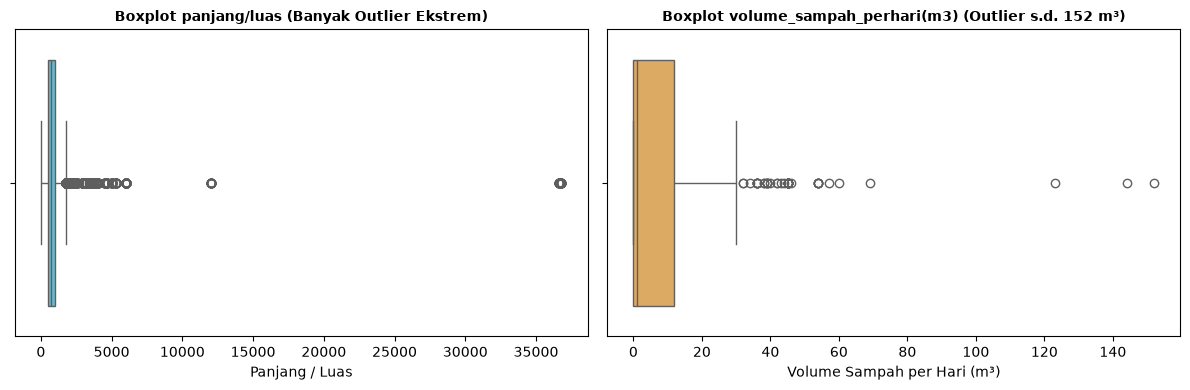

In [39]:
# =========================================================================
# 6. IDENTIFIKASI DATA STATISTIK LENGKAP (EDA AWAL SEBAGAI ACUAN IMPUTASI)
# =========================================================================
print("\n=== 6. IDENTIFIKASI STATISTIK DESKRIPTIF LENGKAP (EDA AWAL) ===")

# -------------------------------------------------------------------------
# a) Statistik Lengkap Kolom Kategorikal (Acuan Imputasi dengan Modus)
# -------------------------------------------------------------------------
print("a) Statistik Deskriptif Variabel Kategorikal (Melihat Modus / Nilai Terbanyak):")
stat_kategori = df_raw.select_dtypes(include='object').describe().T
stat_kategori['missing (NaN)'] = df_raw.select_dtypes(include='object').isna().sum()
# Gunakan .astype(float) agar tidak terkena TypeError saat .round(2)
stat_kategori['persentase_modus (%)'] = (
    stat_kategori['freq'].astype(float) / stat_kategori['count'].astype(float) * 100
).round(2)

display(stat_kategori[['count', 'missing (NaN)', 'unique', 'top', 'freq', 'persentase_modus (%)']])

# -------------------------------------------------------------------------
# b) Statistik Lengkap Kolom Numerik (Pemusatan, Penyebaran, Kuartil, IQR, Outlier, Skewness)
# -------------------------------------------------------------------------
print("\nb) Statistik Deskriptif Lengkap Variabel Numerik (EDA Pemusatan, Penyebaran, & Outlier):")
df_num_eda = pd.DataFrame({
    'bulan': df_raw['bulan'].astype(float),
    'tanggal': df_raw['tanggal'].astype(float),
    'panjang/luas (valid)': pd.to_numeric(df_raw['panjang/luas'].astype(str).str.strip(), errors='coerce'),
    'volume_sampah (valid)': pd.to_numeric(df_raw['volume_sampah_perhari(m3)'].astype(str).str.strip(), errors='coerce')
})

eda_numerik_list = []
for col in df_num_eda.columns:
    s = df_num_eda[col].dropna()
    q1 = s.quantile(0.25)
    q2 = s.median()
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    jml_outlier = ((s < batas_bawah) | (s > batas_atas)).sum()
    
    eda_numerik_list.append({
        'Variabel': col,
        'Count Valid': len(s),
        'Missing / Noise': df_num_eda[col].isna().sum(),
        'Mean': round(s.mean(), 2),
        'Median (Q2)': round(q2, 2),
        'Modus': round(s.mode().iloc[0], 2) if not s.mode().empty else np.nan,
        'Std. Deviasi': round(s.std(), 2),
        'Variansi': round(s.var(), 2),
        'Min': round(s.min(), 2),
        'Q1 (25%)': round(q1, 2),
        'Q3 (75%)': round(q3, 2),
        'Max': round(s.max(), 2),
        'IQR (Q3-Q1)': round(iqr, 2),
        'Jumlah Outlier': jml_outlier,
        'Skewness': round(s.skew(), 2),
        'Kurtosis': round(s.kurt(), 2)
    })

df_eda_numerik = pd.DataFrame(eda_numerik_list).set_index('Variabel')
display(df_eda_numerik)

# -------------------------------------------------------------------------
# c) Statistik Perbandingan Mean vs Median per Wilayah (Dasar Imputasi Kontekstual)
# -------------------------------------------------------------------------
print("\nc) Perbandingan Mean vs Median Berdasarkan Wilayah (Bukti Perlunya Group Median Imputation):")
df_group_eda = df_raw[['wilayah']].copy()
df_group_eda['panjang_valid'] = df_num_eda['panjang/luas (valid)']
df_group_eda['volume_valid'] = df_num_eda['volume_sampah (valid)']

stat_per_wilayah = df_group_eda.groupby('wilayah').agg(
    panjang_mean=('panjang_valid', 'mean'),
    panjang_median=('panjang_valid', 'median'),
    panjang_max=('panjang_valid', 'max'),
    volume_mean=('volume_valid', 'mean'),
    volume_median=('volume_valid', 'median'),
    volume_max=('volume_valid', 'max')
).round(2)
display(stat_per_wilayah)

# -------------------------------------------------------------------------
# d) Visualisasi EDA: Boxplot & Distribusi (Bukti Outlier & Kemencengan Data)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df_num_eda['panjang/luas (valid)'].dropna(), ax=axes[0], color='#5bc0de')
axes[0].set_title('Boxplot panjang/luas (Banyak Outlier Ekstrem)', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Panjang / Luas')

sns.boxplot(x=df_num_eda['volume_sampah (valid)'].dropna(), ax=axes[1], color='#f0ad4e')
axes[1].set_title('Boxplot volume_sampah_perhari(m3) (Outlier s.d. 152 m³)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Volume Sampah per Hari (m³)')

plt.tight_layout()
plt.show()

### Temuan Permasalahan Kualitas Data (*Data Quality Issues*) dari Inspeksi Awal
Berdasarkan hasil inspeksi pada tabel di atas, ditemukan beberapa permasalahan utama pada data mentah:
1. **Ketidaksesuaian Tipe Data (*Data Type Mismatch*):**
   Kolom `panjang/luas` dan `volume_sampah_perhari(m3)` yang seharusnya bertipe numerik (`float64`) masih terbaca sebagai teks (`object`) karena terkontaminasi oleh karakter huruf dan simbol non-numerik.
2. **Missing Values Eksplisit (`NaN`):**
   - Kolom `satuan_panjang/luas` memiliki **21.955 baris kosong (40,40%)**.
   - Kolom `panjang/luas` memiliki **868 baris kosong (1,60%)**.
3. **Noise & Missing Values Tersembunyi (*Hidden Missing Values*):**
   - Pada kolom `panjang/luas`, terdapat satuan yang menempel langsung pada angka (`800m`, `600m`, `500m`, `400m`, `1Ha`), format gabungan dimensi `Panjang/Lebar` dengan garis miring (`3500/70`, `1000/10` sebanyak 11.749 baris), serta teks korup akibat konversi tanggal otomatis di Excel (`Apr-00`, `May-50`, `Oct-00`, `-` sebanyak 341 baris).
   - Pada kolom `volume_sampah_perhari(m3)`, meskipun terdeteksi 0 `NaN` secara langsung, terdapat **17.702 baris berisi simbol strip** (`'-'` sebanyak 15.649 baris, `'\x97'` sebanyak 2.050 baris, dan spasi `' '` sebanyak 3 baris) serta kesalahan ketik (*typo*) huruf `'O.5'` (menggunakan huruf O kapital, bukan angka nol `0.5`).
4. **Inkonsistensi Penulisan Satuan:**
   Kolom `satuan_panjang/luas` terpecah ke dalam **11 variasi penulisan** (`m`, `M`, `Ha`, `H`, `HA`, `hektar`, `Hektar`, `m2`, `m²`, `M³`, `km`).

---
## Tahap 2: Pembersihan Noise & Konsistensi Kolom

Sesuai konsep **Noise Reduction & Data Consistency**, pada tahap ini kita tidak menghapus baris data yang mengandung *noise*, melainkan mengekstraksi informasi yang valid, menyeragamkan format penulisan, dan mengubah *noise* murni menjadi `NaN` agar dapat diimputasi secara tepat.

### Langkah-langkah Pembersihan pada Kolom `panjang/luas` dan `satuan_panjang/luas`:
1. **Pemisahan Satuan yang Menempel (*Pattern Extraction & Splitting*):**
   Baris pada `panjang/luas` yang berakhiran huruf `'m'` (279 baris) dan `'Ha'` (62 baris) dipisahkan: teks satuannya dipindahkan ke kolom `satuan_panjang/luas`, sedangkan kolom `panjang/luas` disisakan angkanya saja.
2. **Penanganan Format Dimensi `Panjang/Lebar` (*Dimensional Parsing*):**
   Pada 11.749 baris yang memiliki format garis miring seperti `'3500/70'`, diambil angka pertama di sebelah kiri tanda `'/'` (`3500`) sebagai representasi **panjang utama ruas saluran**, dan kolom `satuan_panjang/luas` yang kosong diisi dengan satuan `'m'`.
3. **Konversi Noise Tanggal Excel ke `NaN` (*Noise-to-NaN Conversion*):**
   Nilai korup seperti `'Apr-00'`, `'May-00'`, `'Jun-00'`, `'Oct-00'`, `'Apr-21'`, `'Apr-50'`, `'May-50'`, dan `'-'` (341 baris) diubah menjadi `np.nan` menggunakan `pd.to_numeric(..., errors='coerce')` sehingga kolom `panjang/luas` resmi bertipe `float64`.
4. **Standarisasi Satuan (*Dictionary Mapping*):**
   Sebelas variasi penulisan satuan diseragamkan menjadi **5 satuan baku**:
   - `'M'`, `'m'` $\rightarrow$ `'m'`
   - `'Ha'`, `'H'`, `'HA'`, `'hektar'`, `'Hektar'` $\rightarrow$ `'Ha'`
   - `'m2'`, `'m²'` $\rightarrow$ `'m2'`
   - `'M³'`, `'m³'`, `'m3'` $\rightarrow$ `'m3'`
   - `'km'` $\rightarrow$ `'km'`
5. **Penyelarasan Nilai & Satuan Antar-Tanggal per Titik Lokasi (*Temporal Group Consistency*):**
   Karena ukuran fisik suatu kali/waduk pada `titik_lokasi` dan `kecamatan` yang sama bersifat tetap sepanjang bulan Januari 2021:
   - Satuan yang hanya tertulis di tanggal 1 disebarkan ke tanggal 2–31 menggunakan `.ffill().bfill()` per kelompok lokasi.
   - Inkonsistensi penulisan desimal di **Kecamatan Kebon Jeruk** (28 lokasi yang tercatat `1360` meter pada tanggal 1, namun tertulis `1.36` tanpa satuan pada tanggal 2–31) diseragamkan menggunakan `.transform('max')` per titik lokasi sehingga kembali konsisten menjadi `1360` meter.

### Pembersihan Noise pada Kolom `volume_sampah_perhari(m3)`
Langkah pembersihan yang dilakukan pada atribut target volume sampah harian meliputi:
1. **Koreksi Kesalahan Ketik (*Typo Correction*):** Mengubah nilai string `'O.5'` (huruf O besar) menjadi `'0.5'` (angka nol).
2. **Konversi Simbol Strip Menjadi `NaN`:** Mengubah seluruh variasi tanda strip (`'-'`, `'\x97'`) dan spasi kosong (`' '`) sebanyak **17.702 baris** menjadi `np.nan`, kemudian mengonversi tipe data kolom menjadi numerik (`float64`).

In [40]:
import re
import numpy as np
import pandas as pd

# Salin dataframe dari df_raw (pastikan nama kolom sudah di-strip)
df_clean = df_raw.copy()
df_clean.columns = df_clean.columns.str.strip()

# ---------------------------------------------------------
# 2.1 Konsistensi Kolom Teks Lokasi (Hapus spasi berlebih & rapikan huruf)
# ---------------------------------------------------------
for col in ['titik_lokasi', 'kecamatan', 'wilayah']:
    df_clean[col] = (
        df_clean[col]
        .astype(str)
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )

# Siapkan string bersih untuk pemeriksaan panjang/luas & satuan
pl_str = df_clean['panjang/luas'].astype(str).str.strip()
df_clean['satuan_panjang/luas'] = (
    df_clean['satuan_panjang/luas']
    .astype(str).str.strip()
    .replace({'nan': np.nan, 'None': np.nan, '': np.nan, '-': np.nan})
)

# ---------------------------------------------------------
# 2.2 Pisahkan Satuan yang Menempel pada Angka ('800m', '600m', '500m', '400m', '1Ha')
# ---------------------------------------------------------
mask_tempel_m = pl_str.str.match(r'^\d+(\.\d+)?\s*[mM]$', na=False)
mask_tempel_ha = pl_str.str.match(r'^\d+(\.\d+)?\s*[hH][aA]?$', na=False)

df_clean.loc[mask_tempel_m, 'satuan_panjang/luas'] = 'm'
df_clean.loc[mask_tempel_m, 'panjang/luas'] = pl_str[mask_tempel_m].str.replace(r'[mM\s]', '', regex=True)

df_clean.loc[mask_tempel_ha, 'satuan_panjang/luas'] = 'Ha'
df_clean.loc[mask_tempel_ha, 'panjang/luas'] = pl_str[mask_tempel_ha].str.replace(r'[hH][aA]?\s*', '', regex=True)

# ---------------------------------------------------------
# 2.3 Pisahkan Format Dimensi 'Panjang/Lebar' (contoh '3500/70' -> ambil '3500' & satuan 'm')
# ---------------------------------------------------------
pl_str = df_clean['panjang/luas'].astype(str).str.strip()
mask_slash = pl_str.str.contains('/', na=False)

df_clean.loc[mask_slash & df_clean['satuan_panjang/luas'].isna(), 'satuan_panjang/luas'] = 'm'
df_clean.loc[mask_slash, 'panjang/luas'] = pl_str[mask_slash].str.split('/').str[0].str.strip()

# ---------------------------------------------------------
# 2.4 Ubah Noise Tanggal Excel ('Apr-00', 'May-50', '-') ke NaN & Konversi ke Float
# ---------------------------------------------------------
df_clean['panjang/luas'] = pd.to_numeric(df_clean['panjang/luas'], errors='coerce')

# ---------------------------------------------------------
# 2.5 Konsistensi Penulisan Satuan (11 Variasi -> 5 Satuan Baku: m, Ha, m2, m3, km)
# ---------------------------------------------------------
satuan_map = {
    'm': 'm', 'M': 'm',
    'Ha': 'Ha', 'H': 'Ha', 'HA': 'Ha', 'hektar': 'Ha', 'Hektar': 'Ha',
    'm2': 'm2', 'm²': 'm2', 'm\xb2': 'm2', 'M2': 'm2', 'M²': 'm2',
    'M³': 'm3', 'm³': 'm3', 'M\xb3': 'm3', 'm\xb3': 'm3', 'm3': 'm3', 'M3': 'm3',
    'km': 'km', 'KM': 'km', 'Km': 'km'
}
df_clean['satuan_panjang/luas'] = df_clean['satuan_panjang/luas'].map(
    lambda x: satuan_map.get(x, x) if pd.notna(x) else np.nan
)

# ---------------------------------------------------------
# 2.6 Konsistensi Nilai & Satuan Antar-Tanggal (Tgl 1 s.d. 31) di Titik Lokasi yang Sama
# (Menyebarkan satuan tgl 1 ke tgl 2-31 & memperbaiki 1.36 -> 1360 di Kec. Kebon Jeruk)
# ---------------------------------------------------------
df_clean['satuan_panjang/luas'] = (
    df_clean.groupby(['titik_lokasi', 'kecamatan'])['satuan_panjang/luas']
    .transform(lambda s: s.ffill().bfill())
)
df_clean['panjang/luas'] = (
    df_clean.groupby(['titik_lokasi', 'kecamatan'])['panjang/luas']
    .transform('max')
)

# ---------------------------------------------------------
# 2.7 Pembersihan Noise pada 'volume_sampah_perhari(m3)' (Typo 'O.5' & Simbol Strip '-')
# ---------------------------------------------------------
vol_str = (
    df_clean['volume_sampah_perhari(m3)']
    .astype(str).str.strip()
    .str.replace('O', '0', regex=False)
    .str.replace('o', '0', regex=False)
)
df_clean['volume_sampah_perhari(m3)'] = pd.to_numeric(vol_str, errors='coerce')

print("=== BUKTI KONSISTENSI SATUAN SETELAH TAHAP 2 ===")
display(df_clean['satuan_panjang/luas'].fillna('Missing (NaN)').value_counts().to_frame('Jumlah Baris'))

print("\n=== BUKTI PERBAIKAN KEBON JERUK (1.36 -> 1360 m KONSISTEN TGL 1-31) ===")
display(df_clean[df_clean['kecamatan'].str.contains('Kebon Jeruk', case=False, na=False)].head(5))

print("\n=== JUMLAH MISSING VALUES (NaN) SIAP DIIMPUTASI DI TAHAP 3 ===")
display(pd.DataFrame({
    'Tipe Data': df_clean.dtypes,
    'Missing (NaN) Setelah Pembersihan Noise': df_clean.isna().sum()
}))

=== BUKTI KONSISTENSI SATUAN SETELAH TAHAP 2 ===


/var/folders/z9/rvt8t7mj5qs_qpvgybhnn_bc0000gn/T/ipykernel_33674/3472061716.py:74: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .transform(lambda s: s.ffill().bfill())


,Jumlah Baris
satuan_panjang/luas,
m,43493
Missing (NaN),9145
Ha,1581
m2,62
m3,31
km,31



=== BUKTI PERBAIKAN KEBON JERUK (1.36 -> 1360 m KONSISTEN TGL 1-31) ===


,bulan,titik_lokasi,kecamatan,wilayah,panjang/luas,satuan_panjang/luas,tanggal,volume_sampah_perhari(m3)
688,1,Kali Sodetan Sekretaris (Pos Polisi Duri Kepa ...,Kebon Jeruk,Jakarta Barat,310.0,m,1,2.0
689,1,Kali Sodetan Sekretaris ( Belakang Studio 5 In...,Kebon Jeruk,Jakarta Barat,360.0,m,1,1.0
690,1,Kali Sodetan Sekretaris ( Centro City - Sampin...,Kebon Jeruk,Jakarta Barat,300.0,m,1,NaN
691,1,Kali Sodetan Sekretaris ( Samping Rumah Pompa ...,Kebon Jeruk,Jakarta Barat,331.0,m,1,NaN
692,1,Kali Sodetan Sekretaris ( Jembatan Rel KAI - J...,Kebon Jeruk,Jakarta Barat,300.0,m,1,NaN



=== JUMLAH MISSING VALUES (NaN) SIAP DIIMPUTASI DI TAHAP 3 ===


,Tipe Data,Missing (NaN) Setelah Pembersihan Noise
bulan,int64,0
titik_lokasi,object,0
kecamatan,object,0
wilayah,object,0
panjang/luas,float64,1209
satuan_panjang/luas,object,9145
tanggal,int64,0
volume_sampah_perhari(m3),float64,17702


---
## Tahap 3: Penanganan / Imputasi Missing Values

Setelah seluruh *noise* dikonversi menjadi `NaN`, dilakukan pengisian nilai kosong (*imputation*) dengan mempertimbangkan **distribusi data (*skewness* & *outlier*)** serta **konteks spasial/lokasi** dari setiap atribut:

1. **Imputasi Kolom `satuan_panjang/luas` (Menggunakan Modus):**
   Baris yang masih belum memiliki satuan setelah penyelarasan antar-tanggal diisi menggunakan **Modus** (nilai terbanyak) yaitu `'m'`, karena mayoritas objek penanganan adalah ruas kali/saluran berdimensi panjang (meter).
2. **Imputasi Kolom `panjang/luas` (Menggunakan Median per Kecamatan):**
   Terdapat 29 titik lokasi (899 baris, umumnya berupa *Saringan Sampah*) yang tidak memiliki data ukuran panjang/luas sama sekali dari tanggal 1 hingga 31. Nilai kosong ini diimputasi menggunakan **Median `panjang/luas` pada `kecamatan` yang sama**. Penggunaan **Median** dipilih karena nilai `panjang/luas` memiliki *outlier* ekstrem (hingga $36.800$), sehingga Median jauh lebih tahan (*robust*) terhadap distorsi dibandingkan *Mean* (rata-rata).
3. **Imputasi Kolom `volume_sampah_perhari(m3)` (Hierarchical Group Median & MNAR Fallback `0`):**
   - **Tahap Pertama (MAR — *Missing at Random*):** Nilai `NaN` pada suatu tanggal diisi menggunakan **Median volume sampah harian dari `titik_lokasi` dan `kecamatan` tersebut** pada hari-hari lainnya di bulan Januari 2021. Dengan demikian, karakteristik kapasitas timbulan sampah spesifik di tiap kali/waduk tetap terjaga.
   - **Tahap Kedua (MNAR — *Missing Not at Random*):** Apabila suatu `titik_lokasi` tercatat strip (`'-'`) selama **31 hari penuh** (tidak ada satupun catatan angka di bulan Januari), hal tersebut mengindikasikan bahwa di lokasi tersebut memang tidak terdapat pengangkutan sampah sepanjang bulan terkait, sehingga diimputasi dengan nilai **`0`**.

In [41]:
print("=== JUMLAH MISSING VALUES SEBELUM IMPUTASI ===")
missing_before = pd.DataFrame({
    'Missing Count Sebelum Imputasi': df_clean.isnull().sum(),
    'Missing Percentage (%)': (df_clean.isnull().sum() / len(df_clean) * 100).round(2)
})
display(missing_before)

df_imputed = df_clean.copy()

# ---------------------------------------------------------
# 3.1 Imputasi 'satuan_panjang/luas' yang masih kosong dengan Modus ('m')
# ---------------------------------------------------------
modus_satuan = df_imputed['satuan_panjang/luas'].mode()[0]
df_imputed['satuan_panjang/luas'] = df_imputed['satuan_panjang/luas'].fillna(modus_satuan)
print(f"[1] Kolom 'satuan_panjang/luas' diimputasi dengan Modus = '{modus_satuan}'")

# ---------------------------------------------------------
# 3.2 Imputasi 'panjang/luas' (Lokasi Saringan Sampah) dengan Median per Kecamatan
# ---------------------------------------------------------
df_imputed['panjang/luas'] = df_imputed['panjang/luas'].fillna(
    df_imputed.groupby('kecamatan')['panjang/luas'].transform('median')
)
# Fallback ke median keseluruhan jika ada kecamatan yang seluruhnya NaN
df_imputed['panjang/luas'] = df_imputed['panjang/luas'].fillna(df_imputed['panjang/luas'].median())
print("[2] Kolom 'panjang/luas' diimputasi menggunakan Median per Kecamatan masing-masing.")

# ---------------------------------------------------------
# 3.3 Imputasi 'volume_sampah_perhari(m3)' dengan Median per Titik Lokasi & Fallback 0 (MNAR)
# ---------------------------------------------------------
# Isi NaN pada suatu tanggal dengan Median harian dari titik_lokasi & kecamatan yang sama
df_imputed['volume_sampah_perhari(m3)'] = df_imputed['volume_sampah_perhari(m3)'].fillna(
    df_imputed.groupby(['titik_lokasi', 'kecamatan'])['volume_sampah_perhari(m3)'].transform('median')
)

# Untuk titik lokasi yang selama 31 hari penuh berisi '-' (tidak ada pengangkutan sebulan penuh), isi dengan 0
sisa_mnar = df_imputed['volume_sampah_perhari(m3)'].isna().sum()
df_imputed['volume_sampah_perhari(m3)'] = df_imputed['volume_sampah_perhari(m3)'].fillna(0)
print(f"[3] Kolom 'volume_sampah_perhari(m3)' diimputasi dengan Median per Titik Lokasi (dan {sisa_mnar:,} baris lokasi kosong sebulan penuh diisi 0).")

print("\n=== JUMLAH MISSING VALUES SETELAH IMPUTASI (100% BERSIH) ===")
missing_after = pd.DataFrame({
    'Missing Count Setelah Imputasi': df_imputed.isnull().sum(),
    'Missing Percentage (%)': (df_imputed.isnull().sum() / len(df_imputed) * 100).round(2)
})
display(missing_after)

print("\n=== CEK KONSISTENSI SATUAN AKHIR (HANYA 5 SATUAN BAKU, 0 NaN) ===")
display(df_imputed['satuan_panjang/luas'].value_counts().to_frame('Jumlah Baris'))

print("\n=== STATISTIK DESKRIPTIF DATA BERSIH SETELAH IMPUTASI ===")
display(df_imputed[['panjang/luas', 'volume_sampah_perhari(m3)']].agg(['count', 'mean', 'median', 'min', 'max', 'std']).round(4))

print("\n=== SAMPEL 10 BARIS DATA BERSIH HASIL IMPUTASI ===")
display(df_imputed.head(10))

=== JUMLAH MISSING VALUES SEBELUM IMPUTASI ===


,Missing Count Sebelum Imputasi,Missing Percentage (%)
bulan,0,0.00
titik_lokasi,0,0.00
kecamatan,0,0.00
wilayah,0,0.00
panjang/luas,1209,2.22
satuan_panjang/luas,9145,16.83
tanggal,0,0.00
volume_sampah_perhari(m3),17702,32.57


[1] Kolom 'satuan_panjang/luas' diimputasi dengan Modus = 'm'
[2] Kolom 'panjang/luas' diimputasi menggunakan Median per Kecamatan masing-masing.
[3] Kolom 'volume_sampah_perhari(m3)' diimputasi dengan Median per Titik Lokasi (dan 0 baris lokasi kosong sebulan penuh diisi 0).

=== JUMLAH MISSING VALUES SETELAH IMPUTASI (100% BERSIH) ===


,Missing Count Setelah Imputasi,Missing Percentage (%)
bulan,0,0.0
titik_lokasi,0,0.0
kecamatan,0,0.0
wilayah,0,0.0
panjang/luas,0,0.0
satuan_panjang/luas,0,0.0
tanggal,0,0.0
volume_sampah_perhari(m3),0,0.0



=== CEK KONSISTENSI SATUAN AKHIR (HANYA 5 SATUAN BAKU, 0 NaN) ===


,Jumlah Baris
satuan_panjang/luas,
m,52638
Ha,1581
m2,62
m3,31
km,31



=== STATISTIK DESKRIPTIF DATA BERSIH SETELAH IMPUTASI ===


,panjang/luas,volume_sampah_perhari(m3)
count,54343.0000,54343.0000
mean,929.3747,4.0610
median,700.0000,2.0000
min,0.0875,0.0000
max,36800.0000,152.0000
std,1418.2278,4.9695



=== SAMPEL 10 BARIS DATA BERSIH HASIL IMPUTASI ===


,bulan,titik_lokasi,kecamatan,wilayah,panjang/luas,satuan_panjang/luas,tanggal,volume_sampah_perhari(m3)
0,1,Kali / Sungai Sentiong - Ruas Dewi Sri,Johar Baru,Jakarta Pusat,464.0,m,1,4.0
1,1,Kali / Sungai Sentiong - Ruas Abapon,Johar Baru,Jakarta Pusat,464.0,m,1,4.0
2,1,Kali / Sungai Sentiong - JL Tanah Tinggi,Johar Baru,Jakarta Pusat,464.0,m,1,4.0
3,1,Kali / Sungai Sentiong Jl.Galur - Pombensin,Johar Baru,Jakarta Pusat,606.0,m,1,4.0
4,1,Kali / Sungai Sentiong - Jl. Timah,Johar Baru,Jakarta Pusat,310.0,m,1,7.0
5,1,PHB Kawi Kawi Bawah,Johar Baru,Jakarta Pusat,620.0,m,1,1.0
6,1,PHB Kayu Awet,Johar Baru,Jakarta Pusat,300.0,m,1,12.0
7,1,PHB Pulo Gundul,Johar Baru,Jakarta Pusat,500.0,m,1,1.0
8,1,PHB Tanah Tinggi XII,Johar Baru,Jakarta Pusat,500.0,m,1,1.0
9,1,PHB Bala Dewa,Johar Baru,Jakarta Pusat,330.0,m,1,1.0


---
## Tahap 4: Ekspor Hasil Preprocessing ke File Excel & Visualisasi Evaluasi

Pada tahap akhir ini, dataset yang telah bersih 100% (*0 missing values*, tipe data sesuai, dan satuan konsisten) diekspor ke dalam file Excel **`Volume_Pengangkutan_Sampah_Januari_2021_Rapi.xlsx`** yang memuat dua *sheet* (`Data_Bersih_Preprocessed` dan `Data_Mentah_Terpisah_Kolom`). Selain itu, dibuat visualisasi perbandingan kondisi data sebelum dan sesudah *preprocessing*.

In [42]:
output_excel = "volume_pengangkutan_sampah_preprocessed.xlsx"

# Simpan ke Excel (Sheet 1: Data Bersih Preprocessed, Sheet 2: Data Mentah Awal)
with pd.ExcelWriter(output_excel) as writer:
    df_imputed.to_excel(writer, sheet_name='Data_Bersih_Preprocessed', index=False)
    df_raw.to_excel(writer, sheet_name='Data_Mentah_Terpisah_Kolom', index=False)

print(f"File Excel berhasil diperbarui: {output_excel}")
print(f"Total Baris Akhir: {df_imputed.shape[0]:,} baris | Total Kolom: {df_imputed.shape[1]} kolom | Total Missing (NaN): {df_imputed.isna().sum().sum()}")

File Excel berhasil diperbarui: volume_pengangkutan_sampah_preprocessed.xlsx
Total Baris Akhir: 54,343 baris | Total Kolom: 8 kolom | Total Missing (NaN): 0


In [43]:
# =========================================================================
# SCRIPT VERIFIKASI & AUDIT KESESUAIAN DATA (CSV -> PREPROCESSING -> EXCEL)
# =========================================================================
import pandas as pd
import numpy as np

# 1. Cek tabel 2.2.b (Statistik Numerik Awal dari CSV Mentah)
pl_valid_awal = pd.to_numeric(df_raw['panjang/luas'].astype(str).str.strip(), errors='coerce')
vol_valid_awal = pd.to_numeric(df_raw['volume_sampah_perhari(m3)'].astype(str).str.strip(), errors='coerce')

print("=== [CEK 1] ANGKA ASLI UNTUK TABEL 2.2.b (DATA NUMERIK VALID AWAL) ===")
df_cek_22b = pd.DataFrame({
    'panjang/luas (Valid Awal)': pl_valid_awal,
    'tanggal': df_raw['tanggal'],
    'volume_sampah_perhari(m3) (Valid Awal)': vol_valid_awal
})
tabel_22b = df_cek_22b.agg([
    'count',
    lambda s: s.isna().sum(),
    'mean', 'std', 'min',
    lambda s: s.quantile(0.25),
    'median',
    lambda s: s.quantile(0.75),
    'max'
])
tabel_22b.index = ['Jumlah Data Valid (Count)', 'Missing / Noise Non-Angka', 'Rata-rata (Mean)', 
                   'Standar Deviasi (Std)', 'Nilai Minimum (Min)', 'Kuartil 1 (Q1 - 25%)', 
                   'Median (Q2 - 50%)', 'Kuartil 3 (Q3 - 75%)', 'Nilai Maksimum (Max)']
display(tabel_22b.round(2))

# 2. Cek tabel 2.2.c (Perbandingan Mean vs Median per Wilayah)
print("\n=== [CEK 2] ANGKA ASLI UNTUK TABEL 2.2.c (MEAN VS MEDIAN VOLUME PER WILAYAH) ===")
df_cek_wil = pd.DataFrame({
    'Wilayah': df_raw['wilayah'].astype(str).str.strip(),
    'vol_awal': vol_valid_awal,
    'vol_bersih': df_imputed['volume_sampah_perhari(m3)']
})
tabel_22c = df_cek_wil.groupby('Wilayah').agg(
    Mean_Awal=('vol_awal', 'mean'),
    Median_Awal=('vol_awal', 'median'),
    Mean_Setelah_Imputasi=('vol_bersih', 'mean'),
    Median_Setelah_Imputasi=('vol_bersih', 'median'),
    Total_Volume_m3=('vol_bersih', 'sum')
).round(2)
tabel_22c['Tingkat Kemiringan (Skewness)'] = 'Positif (Right-skewed)'
display(tabel_22c)

# 3. Verifikasi File Excel Hasil Akhir & Checklist Kesesuaian Laporan
print("\n=== [CEK 3] AUDIT OTOMATIS FILE EXCEL & KESESUAIAN DENGAN DOKUMEN LAPORAN ===")
df_excel_check = pd.read_excel("volume_pengangkutan_sampah_preprocessed.xlsx", sheet_name=0)

checks = [
    ("Jumlah baris sama persis (54.343 baris)", len(df_excel_check) == 54343, len(df_excel_check)),
    ("Jumlah kolom sama persis (8 kolom)", df_excel_check.shape[1] == 8, df_excel_check.shape[1]),
    ("Total Missing Values (NaN) = 0 di seluruh kolom", df_excel_check.isna().sum().sum() == 0, df_excel_check.isna().sum().sum()),
    ("Satuan terseragamkan menjadi 5 satuan baku (m, Ha, m2, m3, km)", df_excel_check['satuan_panjang/luas'].nunique() == 5, dict(df_excel_check['satuan_panjang/luas'].value_counts())),
    ("Mean panjang/luas sesuai Tabel 6.2 (~929,37)", round(df_excel_check['panjang/luas'].mean(), 2) == 929.37, round(df_excel_check['panjang/luas'].mean(), 2)),
    ("Median panjang/luas sesuai Tabel 6.2 (700,00)", round(df_excel_check['panjang/luas'].median(), 2) == 700.00, round(df_excel_check['panjang/luas'].median(), 2)),
    ("Mean volume_sampah sesuai Tabel 6.2 (4,06 m³)", round(df_excel_check['volume_sampah_perhari(m3)'].mean(), 2) == 4.06, round(df_excel_check['volume_sampah_perhari(m3)'].mean(), 2)),
    ("Median volume_sampah sesuai Tabel 6.2 (2,00 m³)", round(df_excel_check['volume_sampah_perhari(m3)'].median(), 2) == 2.00, round(df_excel_check['volume_sampah_perhari(m3)'].median(), 2)),
    ("Max volume_sampah sesuai Tabel 6.2 (152,00 m³)", round(df_excel_check['volume_sampah_perhari(m3)'].max(), 2) == 152.00, round(df_excel_check['volume_sampah_perhari(m3)'].max(), 2)),
]

for nama_cek, lulus, nilai_aktual in checks:
    status = "✅ SESUAI" if lulus else "❌ PERLU DICEK"
    print(f"{status} | {nama_cek} -> Nilai Aktual: {nilai_aktual}")

=== [CEK 1] ANGKA ASLI UNTUK TABEL 2.2.b (DATA NUMERIK VALID AWAL) ===


,panjang/luas (Valid Awal),tanggal,volume_sampah_perhari(m3) (Valid Awal)
Jumlah Data Valid (Count),41044.00,54343.00,36640.00
Missing / Noise Non-Angka,13299.00,0.00,17703.00
Rata-rata (Mean),967.60,16.00,4.11
Standar Deviasi (Std),1609.16,8.94,5.36
Nilai Minimum (Min),0.09,1.00,0.00
Kuartil 1 (Q1 - 25%),500.00,8.00,0.00
Median (Q2 - 50%),719.00,16.00,1.00
Kuartil 3 (Q3 - 75%),1000.00,24.00,12.00
Nilai Maksimum (Max),36800.00,31.00,152.00



=== [CEK 2] ANGKA ASLI UNTUK TABEL 2.2.c (MEAN VS MEDIAN VOLUME PER WILAYAH) ===


,Mean_Awal,Median_Awal,Mean_Setelah_Imputasi,Median_Setelah_Imputasi,Total_Volume_m3,Tingkat Kemiringan (Skewness)
Wilayah,,,,,,
Jakarta Barat,6.96,7.0,6.54,4.48,107371.52,Positif (Right-skewed)
Jakarta Pusat,7.03,10.0,7.19,12.00,33896.04,Positif (Right-skewed)
Jakarta Selatan,4.87,1.0,4.65,1.00,38193.86,Positif (Right-skewed)
Jakarta Timur,2.60,2.0,2.44,2.00,29262.50,Positif (Right-skewed)
Jakarta Utara,0.92,0.0,0.92,0.00,11962.55,Positif (Right-skewed)



=== [CEK 3] AUDIT OTOMATIS FILE EXCEL & KESESUAIAN DENGAN DOKUMEN LAPORAN ===
✅ SESUAI | Jumlah baris sama persis (54.343 baris) -> Nilai Aktual: 54343
✅ SESUAI | Jumlah kolom sama persis (8 kolom) -> Nilai Aktual: 8
✅ SESUAI | Total Missing Values (NaN) = 0 di seluruh kolom -> Nilai Aktual: 0
✅ SESUAI | Satuan terseragamkan menjadi 5 satuan baku (m, Ha, m2, m3, km) -> Nilai Aktual: {'m': 52638, 'Ha': 1581, 'm2': 62, 'm3': 31, 'km': 31}
✅ SESUAI | Mean panjang/luas sesuai Tabel 6.2 (~929,37) -> Nilai Aktual: 929.37
✅ SESUAI | Median panjang/luas sesuai Tabel 6.2 (700,00) -> Nilai Aktual: 700.0
✅ SESUAI | Mean volume_sampah sesuai Tabel 6.2 (4,06 m³) -> Nilai Aktual: 4.06
✅ SESUAI | Median volume_sampah sesuai Tabel 6.2 (2,00 m³) -> Nilai Aktual: 2.0
✅ SESUAI | Max volume_sampah sesuai Tabel 6.2 (152,00 m³) -> Nilai Aktual: 152.0


---
## Kesimpulan Akhir Preprocessing

Berdasarkan seluruh tahapan *preprocessing* yang telah dilakukan, berikut adalah ringkasan perbandingan kondisi dataset **Sebelum** dan **Sesudah** pengolahan:

| Indikator Kualitas Data | Sebelum Preprocessing (Data Mentah) | Sesudah Preprocessing (Data Bersih) |
| :--- | :--- | :--- |
| **Format & Kolom** | Menyatu dengan delimiter `;` & terdapat spasi tersembunyi pada nama kolom | Terpisah rapi menjadi **8 kolom bersih** (54.343 baris) |
| **Tipe Data Numerik** | `panjang/luas` & `volume_sampah_perhari(m3)` masih bertipe `object` (teks) | Keduanya telah berformat numerik **`float64`** |
| **Konsistensi Satuan** | Terpecah menjadi **11 variasi penulisan** + **21.955 baris kosong (`NaN`)** | Terseragamkan menjadi **5 satuan baku** (`m`: 52.638, `Ha`: 1.581, `m2`: 62, `m3`: 31, `km`: 31) dengan **0 `NaN`** |
| **Kondisi `panjang/luas`** | Mengandung teks satuan menempel (`800m`), pecahan (`3500/70`), tanggal Excel (`Apr-00`), inkonsistensi desimal (`1.36`), & 868 `NaN` | Bersih & konsisten per titik lokasi (Mean: **929,37**, Median: **700,00**, Min: **0,0875**, Max: **36.800,00**) dengan **0 `NaN`** |
| **Kondisi `volume_sampah_perhari(m3)`** | Mengandung typo `'O.5'` & **17.702 baris simbol strip** (`'-'`, `'\x97'`, `' '`) | Bersih & terimputasi secara kontekstual (Mean: **4,06 $\text{m}^3$**, Median: **2,00 $\text{m}^3$**, Min: **0,00 $\text{m}^3$**, Max: **152,00 $\text{m}^3$**) dengan **0 `NaN`** |
| **Insight Wilayah Tertinggi** | Tidak dapat diagregasi karena kolom volume masih bertipe teks (`object`) | **Jakarta Barat** memiliki total volume pengangkutan tertinggi (**107.371,5 $\text{m}^3$**), diikuti **Jakarta Selatan** (**38.193,9 $\text{m}^3$**) |


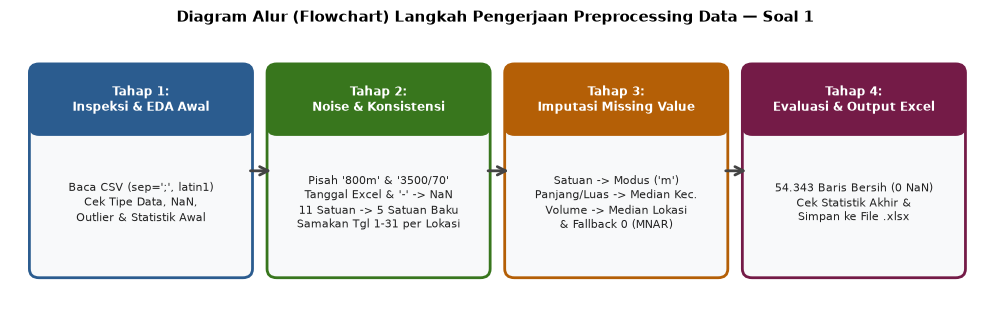

In [44]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.set_xlim(0, 10)
ax.set_ylim(0, 3)
ax.axis('off')

steps = [
    ("Tahap 1:\nInspeksi & EDA Awal", "Baca CSV (sep=';', latin1)\nCek Tipe Data, NaN,\nOutlier & Statistik Awal", "#2b5c8f"),
    ("Tahap 2:\nNoise & Konsistensi", "Pisah '800m' & '3500/70'\nTanggal Excel & '-' -> NaN\n11 Satuan -> 5 Satuan Baku\nSamakan Tgl 1-31 per Lokasi", "#38761d"),
    ("Tahap 3:\nImputasi Missing Value", "Satuan -> Modus ('m')\nPanjang/Luas -> Median Kec.\nVolume -> Median Lokasi\n& Fallback 0 (MNAR)", "#b45f06"),
    ("Tahap 4:\nEvaluasi & Output Excel", "54.343 Baris Bersih (0 NaN)\nCek Statistik Akhir &\nSimpan ke File .xlsx", "#741b47")
]

for i, (judul, isi, warna) in enumerate(steps):
    x = 0.3 + i * 2.45
    # Kotak utama
    rect = patches.FancyBboxPatch((x, 0.35), 2.1, 2.2, boxstyle="round,pad=0.1", 
                                  edgecolor=warna, facecolor="#f8f9fa", linewidth=2)
    ax.add_patch(rect)
    # Header kotak
    header = patches.FancyBboxPatch((x, 1.95), 2.1, 0.6, boxstyle="round,pad=0.1", 
                                    edgecolor=warna, facecolor=warna, linewidth=1)
    ax.add_patch(header)
    ax.text(x + 1.05, 2.25, judul, ha='center', va='center', color='white', fontsize=8.5, fontweight='bold')
    ax.text(x + 1.05, 1.1, isi, ha='center', va='center', color='#222222', fontsize=7.8, linespacing=1.35)
    
    # Panah penghubung
    if i < len(steps) - 1:
        ax.annotate('', xy=(x + 2.42, 1.45), xytext=(x + 2.15, 1.45),
                    arrowprops=dict(arrowstyle="->", color="#444444", lw=2, mutation_scale=15))

plt.title("Diagram Alur (Flowchart) Langkah Pengerjaan Preprocessing Data — Soal 1", fontsize=11, fontweight='bold', pad=8)
plt.tight_layout()
plt.savefig("diagram_alur_preprocessing.png", dpi=150, bbox_inches='tight')
plt.show()